# **Lab 5: Graphs II**
### Programmable mesh graph for automatic routing
***

### Andrés Sanchez-Toril

Put below your tri-lattice function and the hexagonal graph of the "Graphs I" exercises.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def tri_lattice(origin_pos, offset=0):
    ox = origin_pos[0]
    oy = origin_pos[1]

    G = nx.Graph()

    # Añadimos los 12 nodos (del 0 al 11) + el offset
    for n in range(12):
        G.add_node(offset + n)

    # Conexiones originales restando 1 a cada número (para ser 0-11) y sumando el offset
    edges = [(0,2),(0,3),(1,2),(1,3),(2,8),(3,6),(4,6),(4,7),(5,6),(5,7),(7,9),(8,10),(8,11),(9,10),(9,11)]
    G.add_edges_from([(u + offset, v + offset) for u, v in edges])

    side = 1    
    sep = 0.5   
    theta = 4 * np.pi/3
    r, r2 = 1, 0.5

    # Posiciones con el offset en las keys
    pos = {
        offset + 0: (ox + r2*np.cos(np.pi/6) + r*np.cos(-theta), oy + r2*np.sin(np.pi/6) + r*np.sin(-theta)),
        offset + 1: (ox + r*np.cos(-theta), oy + r*np.sin(-theta)),
        offset + 2: (ox + r2*np.cos(np.pi/6), oy + r2*np.sin(np.pi/6)),
        offset + 3: (ox, oy),
        offset + 4: (ox + r*np.cos(theta), oy - sep + r*np.sin(theta)),
        offset + 5: (ox + r2*np.cos(-np.pi/6) + r*np.cos(theta), oy - sep + r2*np.sin(-np.pi/6) + r*np.sin(theta)),
        offset + 6: (ox, oy - sep),
        offset + 7: (ox + r2*np.cos(-np.pi/6), oy - sep + r2*np.sin(-np.pi/6)),
        offset + 8: (ox + side, oy),
        offset + 9: (ox + side, oy - sep),
        offset + 10: (ox + side*2, oy),
        offset + 11: (ox + side * 2, oy - sep),
    }
    
    return G, pos

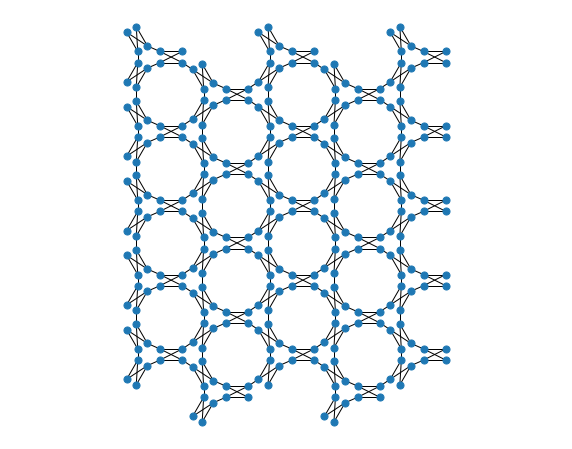

In [3]:
G_hex = nx.Graph()
pos_hex = {}

vn = 5 # number of tri-lattice rows
hn = 5 # number of tri-lattice columns

a1 = 2*np.pi/3
a2 = 4*np.pi/3
# Node positions
side = 1    # length of the MZI horizontally
sep = 0.5   # Vertical separation between the two arms
p0_y = (sep+side)*np.sin(a1) + (-sep/2)*np.cos(a1)
p1_x = (sep+side)*np.cos(a1) - (sep/2)*np.sin(a1)
p5_y = (sep+side)*np.sin(a2) + (sep/2)*np.cos(a2)
p11_x = sep + side

sep = 0.5 # linea para conectar tri-lattices
dx = (p11_x - p1_x) + sep 
dy = (p0_y - p5_y) + sep

i = 0
n_mzi = 0

for row in range(vn):
    for column in range(hn):
        if row % 2 == 0:
            origin = (row * dx, -column * dy)
        else:
            origin = (row * dx , -column * dy -(dy/2))
        # Create tri-lattice at corresponding position    
        G, pos = tri_lattice(origin, i*12)
        # Update nodes and edges of the hexagonal graph
        G_hex.add_nodes_from(G.nodes(data=True))
        G_hex.add_edges_from(G.edges(data=True))
        pos_hex.update(pos)
        
        # Connections between tri-lattices (DO NOT MODIFY)
        if column!=0:
            G_hex.add_edge((i-1)*12 + 5, i*12)
        if row!=0:
            if row%2 == 1:
                if column != hn-1:
                    G_hex.add_edge((i-hn)*12 + 11, i*12 + 1)
                    G_hex.add_edge((i-(hn-1))*12 + 10, i*12 + 4)
                if column == hn-1:
                    G_hex.add_edge((i-hn)*12 + 11, i*12 + 1)
            else: 
                if column != 0:
                    G_hex.add_edge((i-(hn+1))*12 + 11, i*12 + 1)
                    G_hex.add_edge((i-hn)*12 + 10, i*12 + 4)
                if column == 0:
                    G_hex.add_edge((i-hn)*12 + 10, i*12 + 4)

        i = i + 1
        n_mzi = n_mzi + 3

# Find external ports (nodes with less than 3 connections)
max_connections = 3        
ports = [node for node in G_hex.nodes if G_hex.degree[node] < max_connections]

# Draw the graph
plt.figure(figsize=(10,8))
plt.axis('equal')
nx.draw(G_hex, pos=pos_hex, node_size=50)
plt.show()

### Exercise 1
Create a function that find the shortest path in the hexagonal graph, given an input and output port. 

Camino más corto encontrado: [0, 2, 8, 11, 61, 62, 68, 71, 133, 134, 140, 143, 193, 194, 200, 203, 265, 267, 270, 269, 276, 279, 282, 281, 288, 290, 296, 299]


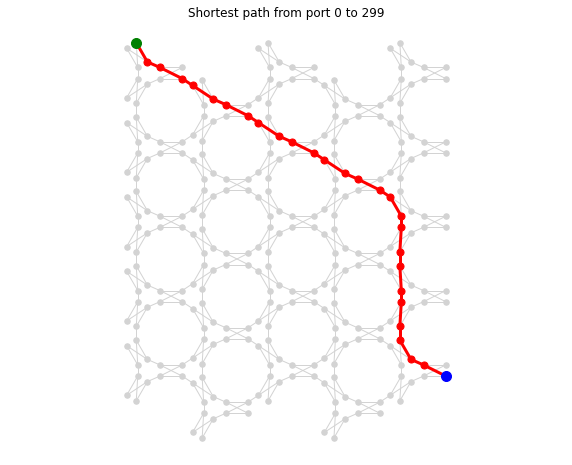

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import math

def find_path(G, pos, input_node, output_node):
    
    # Find path using NetworkX shortest path function
    path = nx.shortest_path(G, source=input_node, target=output_node)
    print(f"Camino más corto encontrado: {path}")

    # Convertimos la lista de nodos (ej: [1, 2, 3]) en lista de aristas (ej: [(1,2), (2,3)])
    path_edges = list(zip(path, path[1:]))

    # Draw the graph and highlight the path
    plt.figure(figsize=(10,8))
    plt.axis('equal')
    
    # 1. Dibujamos el grafo completo en tonos grises para que sirva de fondo
    nx.draw(G, pos=pos, node_size=30, node_color='lightgray', edge_color='lightgray')
    
    # 2. Dibujamos encima los nodos y aristas que forman el camino en color rojo
    nx.draw_networkx_nodes(G, pos, nodelist=path, node_size=50, node_color='red')
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=3)
    
    # 3. Resaltamos los puertos de entrada (Verde) y salida (Azul) para identificarlos bien
    nx.draw_networkx_nodes(G, pos, nodelist=[input_node], node_size=100, node_color='green')
    nx.draw_networkx_nodes(G, pos, nodelist=[output_node], node_size=100, node_color='blue')
    
    plt.title(f"Shortest path from port {input_node} to {output_node}")
    plt.show()
    
    return path # Es útil devolver el camino por si se necesita en los siguientes ejercicios

# Asumiendo que ports, G_hex y pos_hex ya están en memoria por haber corrido el Ejercicio 4
input_port = ports[0]
output_port = ports[-1]

path = find_path(G_hex, pos_hex, input_port, output_port)

### Exercise 2
In a real mesh device, MZI are not perfect due to fabrication deviations, that means they are not in "cross" state, they are in a random state. In order to do a characterization algorithm, find the adjacent MZI nodes that could affect the found path of the Exercise 1. 

Nodos de MZI adyacentes que afectan la ruta: [1, 3, 9, 10, 60, 63, 69, 70, 132, 135, 141, 142, 192, 195, 201, 202, 264, 266, 268, 271, 277, 278, 280, 283, 289, 291, 297, 298]


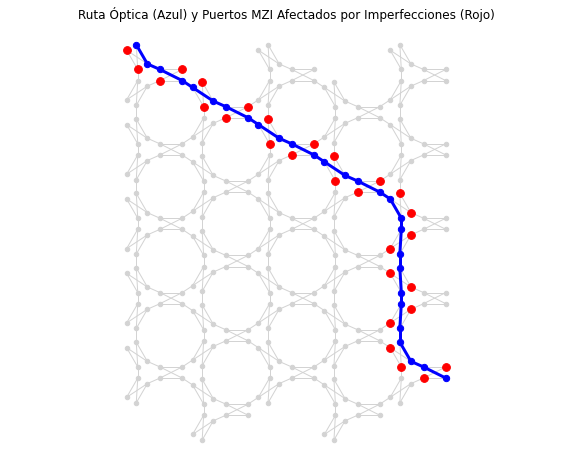

In [9]:
def find_adjacent_mzi_nodes(path):
    adjacent_nodes = set() # Usamos un set para evitar nodos duplicados
    
    # 1. Recorremos todos los puertos (nodos) por los que pasa nuestro camino
    for node in path:
        
        # 2. Encontramos a qué MZI pertenece este nodo (cada MZI tiene 4 puertos)
        mzi_id = node // 4
        
        # 3. Calculamos cuáles son los 4 puertos de este MZI específico
        mzi_ports = [mzi_id * 4, mzi_id * 4 + 1, mzi_id * 4 + 2, mzi_id * 4 + 3]
        
        # 4. Añadimos a nuestra lista los puertos del MZI que NO están siendo 
        # usados por el camino principal (por aquí es por donde hay fugas/ruido)
        for port in mzi_ports:
            if port not in path:
                adjacent_nodes.add(port)
                
    return list(adjacent_nodes)

# Ejecutamos la función usando el 'path' que encontramos en el Ejercicio 1
adjacent_nodes = find_adjacent_mzi_nodes(path)
print(f"Nodos de MZI adyacentes que afectan la ruta: {sorted(adjacent_nodes)}")

# --- Dibujamos el resultado para visualizarlo ---
plt.figure(figsize=(10,8))
plt.axis('equal')

# 1. Malla de fondo (Gris)
nx.draw(G_hex, pos=pos_hex, node_size=20, node_color='lightgray', edge_color='lightgray')

# 2. La ruta óptica ideal (Azul)
path_edges = list(zip(path, path[1:]))
nx.draw_networkx_nodes(G_hex, pos=pos_hex, nodelist=path, node_size=40, node_color='blue')
nx.draw_networkx_edges(G_hex, pos=pos_hex, edgelist=path_edges, edge_color='blue', width=3)

# 3. Nodos afectados por errores de fabricación (Rojo)
nx.draw_networkx_nodes(G_hex, pos=pos_hex, nodelist=adjacent_nodes, node_size=60, node_color='red')

plt.title("Ruta Óptica (Azul) y Puertos MZI Afectados por Imperfecciones (Rojo)")
plt.show()

### Exercise 3
Create a function combining Exercise 1 and 2. Given a mesh graph G, choose a source port, and find the shortest path for all the output MZI ports:

- If a MZI has 2 output ports, use only one of them.

- For each path, the function has to return the adjacent MZI.

--- ANÁLISIS DE RUTAS DESDE EL PUERTO 0 ---

Destino: Puerto 1
  -> Ruta más corta: [0, 2, 1]
  -> Puertos MZI adyacentes (interferencias): [3]

Destino: Puerto 4
  -> Ruta más corta: [0, 3, 6, 4]
  -> Puertos MZI adyacentes (interferencias): [1, 2, 5, 7]

Destino: Puerto 10
  -> Ruta más corta: [0, 2, 8, 10]
  -> Puertos MZI adyacentes (interferencias): [11, 1, 3, 9]

Destino: Puerto 13
  -> Ruta más corta: [0, 3, 6, 5, 12, 14, 13]
  -> Puertos MZI adyacentes (interferencias): [1, 2, 4, 7, 15]

Destino: Puerto 16
  -> Ruta más corta: [0, 3, 6, 5, 12, 15, 18, 16]
  -> Puertos MZI adyacentes (interferencias): [1, 2, 4, 7, 13, 14, 17, 19]

Destino: Puerto 25
  -> Ruta más corta: [0, 3, 6, 5, 12, 15, 18, 17, 24, 26, 25]
  -> Puertos MZI adyacentes (interferencias): [1, 2, 4, 7, 13, 14, 16, 19, 27]

Destino: Puerto 28
  -> Ruta más corta: [0, 3, 6, 5, 12, 15, 18, 17, 24, 27, 30, 28]
  -> Puertos MZI adyacentes (interferencias): [1, 2, 4, 7, 13, 14, 16, 19, 25, 26, 29, 31]

Destino: Puerto 

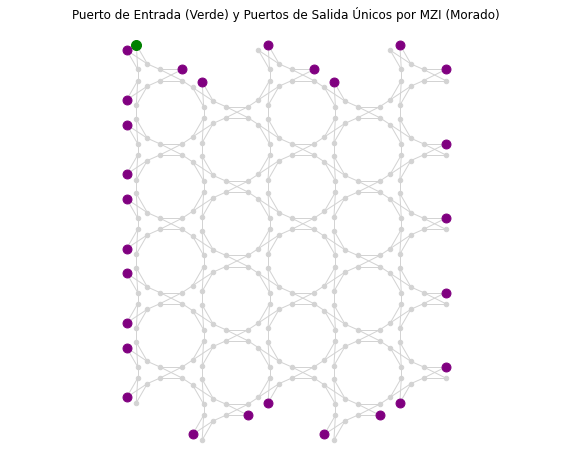

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

def characterize_all_paths(G, source_port, all_external_ports):
    # Diccionario donde guardaremos el resultado final
    results = {}
    
    # 1. Obtenemos todos los posibles puertos de salida (descartamos el de entrada)
    possible_outputs = [p for p in all_external_ports if p != source_port]
    
    # 2. Filtramos para usar solo UN puerto de salida por MZI final
    used_mzi_ids = set()
    valid_output_ports = []
    
    for port in possible_outputs:
        mzi_id = port // 4
        # Si no hemos registrado este MZI todavía, guardamos el puerto y marcamos el MZI como usado
        if mzi_id not in used_mzi_ids:
            used_mzi_ids.add(mzi_id)
            valid_output_ports.append(port)
            
    # 3. Ejecutamos la lógica de los Ejercicios 1 y 2 para cada puerto de salida válido
    for target_port in valid_output_ports:
        try:
            # --- Lógica Ejercicio 1 (Ruta) ---
            path = nx.shortest_path(G, source=source_port, target=target_port)
            
            # --- Lógica Ejercicio 2 (Nodos adyacentes/fugas) ---
            adjacent_nodes = set()
            for node in path:
                mzi_id = node // 4
                mzi_ports = [mzi_id * 4, mzi_id * 4 + 1, mzi_id * 4 + 2, mzi_id * 4 + 3]
                
                for p in mzi_ports:
                    if p not in path:
                        adjacent_nodes.add(p)
                        
            # Guardamos el resultado en nuestro diccionario usando el puerto de destino como clave
            results[target_port] = {
                'path': path,
                'adjacent_nodes': list(adjacent_nodes)
            }
            
        except nx.NetworkXNoPath:
            # Esto maneja el error silenciosamente si por casualidad un nodo estuviera aislado
            pass
            
    return results

# --- Prueba de la función ---

# Tomamos el primer puerto como entrada y le pasamos todos los puertos externos
input_port = ports[0]
all_characterizations = characterize_all_paths(G_hex, input_port, ports)

# --- Imprimimos los resultados en formato legible ---
print(f"--- ANÁLISIS DE RUTAS DESDE EL PUERTO {input_port} ---")
for target, data in all_characterizations.items():
    print(f"\nDestino: Puerto {target}")
    print(f"  -> Ruta más corta: {data['path']}")
    print(f"  -> Puertos MZI adyacentes (interferencias): {data['adjacent_nodes']}")

# --- Opcional: Visualizamos los puertos finales que ha elegido el algoritmo ---
plt.figure(figsize=(10,8))
plt.axis('equal')

# Malla base
nx.draw(G_hex, pos=pos_hex, node_size=20, node_color='lightgray', edge_color='lightgray')

# Destacamos el puerto de entrada en Verde
nx.draw_networkx_nodes(G_hex, pos=pos_hex, nodelist=[input_port], node_size=100, node_color='green')

# Destacamos los puertos de salida seleccionados en Morado
selected_targets = list(all_characterizations.keys())
nx.draw_networkx_nodes(G_hex, pos=pos_hex, nodelist=selected_targets, node_size=80, node_color='purple')

plt.title("Puerto de Entrada (Verde) y Puertos de Salida Únicos por MZI (Morado)")
plt.show()